# NMS propio, cabeza de pertenencia y union del pipeline

**Entradas:** `splits/dataset.csv`, el manifiesto de cortes positivos, las definiciones de los notebooks 02, 06, 07 y 10, los modulos `deteccion_grid.py`, `cbam_modulos.py`, `pertenencia.py`, `pipeline_pengwin.py`, `evidencias_nms.py` y el checkpoint de 12_entrenamiento_multitarea en `evidencias/entrenamiento_multitarea/`.

**Salidas:** `evidencias/nms_pertenencia/` y `evidencias/entrenamiento_multitarea/cabeza_pertenencia.pt`.

Este notebook conecta las piezas de semana 10 que me corresponden, sobre el modelo multitarea entrenado por Miguel:

1. **NMS propio por clase** (`deteccion_grid.nms_por_clase`): filtra cajas duplicadas de la cabeza grid.
2. **Cabeza de pertenencia** (`pertenencia.PertenenciaHead`): tercera cabeza sobre el backbone compartido; asigna cada fragmento a sacro, coxal izquierdo o coxal derecho. Se entrena en una **etapa D** con el tronco de Miguel congelado.
3. **Unión detección → NMS → segmentación → pertenencia** (`pipeline_pengwin.py`), con salidas vacías probadas.

Pruebas automáticas: `python -m unittest tests.test_nms tests.test_pertenencia tests.test_pipeline -v`.

> Si el checkpoint de Miguel no está en `evidencias/entrenamiento_multitarea/`, el notebook corre con pesos **sin entrenar** y lo dice en cada resultado: en ese caso demuestra que el sistema está conectado, no su desempeño.

## 1. Configuracion

Rutas relativas a la raiz del repositorio y lectura de los archivos que generan los notebooks anteriores. Las definiciones compartidas se cargan por nombre desde el notebook donde viven (`definiciones_notebooks.cargar_definiciones`), sin ejecutar sus celdas de prueba.

In [1]:
from pathlib import Path
import gc
import sys

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import SimpleITK as sitk
import torch
import torch.nn as nn

# Raiz del repositorio: funciona si el kernel arranca en notebooks/ o en la raiz.
BASE_DIR = next(p for p in (Path.cwd(), *Path.cwd().parents) if (p / "requirements.txt").is_file())
if str(BASE_DIR) not in sys.path:
    sys.path.insert(0, str(BASE_DIR))  # modulos .py del proyecto

from definiciones_notebooks import cargar_definiciones

SPLITS_DIR = BASE_DIR / "splits"
EVIDENCE_DIR = BASE_DIR / "evidencias"
NOTEBOOKS_DIR = BASE_DIR / "notebooks"

def to_repo_relative(path):
    """Guarda rutas portables dentro del repositorio."""
    path = Path(path)
    try:
        return path.relative_to(BASE_DIR).as_posix()
    except ValueError:
        return path.as_posix()


def resolve_repo_path(path):
    """Permite leer rutas relativas o absolutas sin romper compatibilidad."""
    path = Path(path)
    if path.is_absolute():
        return path
    return BASE_DIR / path

# Dataset curado y splits generados por 01_dataset_splits.ipynb
df = pd.read_csv(SPLITS_DIR / "dataset.csv", dtype={"case_id": str})
# Indice de cortes positivos generado por 06_targets_deteccion.ipynb
slice_manifest = pd.read_csv(EVIDENCE_DIR / "datos_targets" / "manifest_cortes_positivos.csv", dtype={"case_id": str})

cargar_definiciones(NOTEBOOKS_DIR / "Ventaneo_hu.ipynb", {"load_mha", "apply_hu_window", "enhance_bone_contrast"}, destino=globals())
cargar_definiciones(NOTEBOOKS_DIR / "Targets_deteccion.ipynb", {"instance_to_semantic", "boxes_from_semantic", "letterbox_pair", "build_detection_target",
     "PengwinDetectionDataset", "detection_collate"},
                    valores={"CLASS_ID_TO_NAME", "TARGET_COLORS"}, destino=globals())
cargar_definiciones(NOTEBOOKS_DIR / "Backbone.ipynb", {"FundidoraPC", "FundidoraPCPlus", "build_backbone", "theoretical_receptive_field",
     "count_parameters", "make_models"}, destino=globals())
cargar_definiciones(NOTEBOOKS_DIR / "Segmentacion_instancias.ipynb",
                    {"backbone_feature_pyramid", "build_detection_region_priors", "SegmentationConvBlock",
                     "SkipFusionBlock", "CenterOffsetSkipDecoder", "decode_center_offset_instances",
                     "restore_letterbox_label_mask", "link_slice_instances_to_volume"}, destino=globals())

SEED = 42
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("torch", torch.__version__, "| dispositivo:", DEVICE)

torch 2.11.0+cu128 | dispositivo: cuda


In [2]:
import ast
import json
import subprocess
import time

from deteccion_grid import NMS_CONFIG, GridDetectionHead, decode_predictions, nms_por_clase, postprocess
from cbam_modulos import CBAM, CompuertaResidualCBAM
from pertenencia import (PertenenciaHead, cargar_submodulo, entrenar_pertenencia, perdida_pertenencia,
                         precalcular_cache_pertenencia, predecir_cache, targets_pertenencia, metricas_pertenencia)
from pipeline_pengwin import (CONFIG_PIPELINE, evaluar_pertenencia, inferir_cortes, inferir_volumen,
                              resumen_evaluacion_pertenencia)
from evidencias_nms import barrido_nms, figura_antes_despues, logits_oraculo

ENTRENAMIENTO_DIR = EVIDENCE_DIR / "entrenamiento_multitarea"
FABIAN_EVIDENCE_DIR = EVIDENCE_DIR / "nms_pertenencia"
FABIAN_EVIDENCE_DIR.mkdir(parents=True, exist_ok=True)
print("Configuración del pipeline:", CONFIG_PIPELINE)

Configuración del pipeline: {'score_thresh': 0.05, 'iou_thresh': 0.5, 'max_det_per_class': 1, 'center_threshold': 0.25, 'min_center_distance': 7, 'min_instance_pixels': 1, 'output_size': (256, 256)}


## 2. Cargar el modelo multitarea entrenado (Miguel)

- Se busca `modelo_multitarea_final.pt` (exportado) o `best_C_conjunto.pth` (checkpoint de la etapa C) en `evidencias/entrenamiento_multitarea/`. Los pesos no se suben a GitHub (`.gitignore`): hay que copiarlos a mano.
- Miguel entrenó con el decoder **sin** skip connections (`CenterOffsetSegmentationDecoder`), que después fue reemplazado en 10_segmentacion_instancias por la versión con skips. Para cargar el checkpoint con la arquitectura exacta con la que se entrenó, la definición se recupera del **commit registrado en su `config.json`** (`git_commit`); en ese commit el código vivía en `proyecto_pengwin.ipynb`, antes de partirlo en esta serie de notebooks. No se copia código: se lee de la historia de Git.
- Dos adaptadores conectan el modelo al contrato del pipeline: el backbone de Miguel devuelve `(pooled, f4)` y su decoder recibe solo `f4`.

In [3]:
def recuperar_definicion_de_git(commit, archivo, nombre):
    """Ejecuta en este notebook la clase/función `nombre` tal como estaba en `archivo` en el `commit` dado."""
    texto = subprocess.run(["git", "show", f"{commit}:{archivo}"], cwd=BASE_DIR, capture_output=True,
                           text=True, encoding="utf-8", check=True).stdout
    for celda in json.loads(texto)["cells"]:
        if celda["cell_type"] != "code":
            continue
        fuente = "".join(celda["source"])
        try:
            arbol = ast.parse(fuente)
        except SyntaxError:
            continue
        for nodo in arbol.body:
            if getattr(nodo, "name", None) == nombre:
                exec(ast.get_source_segment(fuente, nodo), globals())
                return globals()[nombre]
    raise LookupError(f"{nombre} no está en {archivo} del commit {commit}")


class DecoderSinSkips(nn.Module):
    """Adaptador: el decoder de Miguel recibe solo f4; el pipeline le pasa (imagen, pirámide, priors)."""
    def __init__(self, decoder):
        super().__init__()
        self.decoder = decoder

    def forward(self, image, features, region_priors, output_size=(256, 256)):
        return self.decoder(features[-1], region_priors, output_size=output_size)


def features_backbone_miguel(backbone, x):
    """Adaptador: el backbone devuelve (pooled, f4); el pipeline espera una pirámide cuyo último nivel es f4."""
    return [None, None, None, backbone(x)[1]]


def preprocesar_corte(corte_hu, output_size=256):
    """Mismo preprocesamiento del dataset: ventaneo HU -> CLAHE -> letterbox. Devuelve (imagen 256x256, transform)."""
    imagen = enhance_bone_contrast(apply_hu_window(corte_hu))
    imagen_256, _, transform = letterbox_pair(imagen, np.zeros(corte_hu.shape, dtype=np.int16), output_size)
    return imagen_256, transform


MODELO_PATH = next((p for p in (ENTRENAMIENTO_DIR / "modelo_multitarea_final.pt",
                                ENTRENAMIENTO_DIR / "best_C_conjunto.pth") if p.is_file()), None)
PESOS_ENTRENADOS = DECODER_OK = False
comunes = {"priors_fn": build_detection_region_priors, "decode_fn": decode_center_offset_instances,
           "restore_fn": restore_letterbox_label_mask, "link_fn": link_slice_instances_to_volume,
           "preprocess_fn": preprocesar_corte}

if MODELO_PATH is not None:
    try:
        payload = torch.load(MODELO_PATH, map_location="cpu", weights_only=True)
    except Exception:                       # checkpoint de entrenamiento: trae optimizador y config (archivo del equipo)
        payload = torch.load(MODELO_PATH, map_location="cpu", weights_only=False)
    sd = payload["model_state_dict"]
    cfg_entrenamiento = payload.get("training_config", payload.get("config", {}))
    backbone_name = payload.get("architecture", {}).get("backbone_name", cfg_entrenamiento.get("BACKBONE_NAME", "plus"))
    commit_entrenamiento = cfg_entrenamiento.get("git_commit", "0db074a")

    backbone_m = cargar_submodulo(build_backbone(backbone_name, in_channels=1), sd, "backbone.").to(DEVICE).eval()
    cbam_m = cargar_submodulo(CompuertaResidualCBAM(CBAM(256)), sd, "cbam.").to(DEVICE).eval()
    det_head_m = cargar_submodulo(GridDetectionHead(), sd, "det_head.").to(DEVICE).eval()
    PESOS_ENTRENADOS = True
    try:
        DecoderEntrenado = recuperar_definicion_de_git(commit_entrenamiento, "proyecto_pengwin.ipynb",
                                                       "CenterOffsetSegmentationDecoder")
        decoder_m = cargar_submodulo(DecoderEntrenado(in_channels=256), sd, "seg_decoder.").to(DEVICE).eval()
        DECODER_OK = True
    except Exception as exc:
        decoder_m = None
        print(f"AVISO: no se pudo reconstruir el decoder entrenado ({type(exc).__name__}: {exc}).")
    componentes = {"backbone": backbone_m, "cbam": cbam_m, "det_head": det_head_m,
                   "seg_decoder": DecoderSinSkips(decoder_m) if DECODER_OK else None,
                   "cls_head": None, "features_fn": features_backbone_miguel, **comunes}
    sel = payload.get("selected_from", {"stage": payload.get("stage"), "epoch": payload.get("epoch")})
    etapa = sel.get("stage")
    etapa = etapa.get("name") if isinstance(etapa, dict) else etapa
    print(f"Modelo de Miguel cargado desde {MODELO_PATH.name} | backbone '{backbone_name}' | "
          f"commit {commit_entrenamiento} | etapa {etapa}, época {sel.get('epoch')}")
    print("Decoder entrenado:", "OK" if DECODER_OK else "NO disponible")
else:
    torch.manual_seed(SEED)
    backbone_sin_entrenar = build_backbone("base", in_channels=1).to(DEVICE).eval()
    torch.manual_seed(SEED)
    componentes = {"backbone": backbone_sin_entrenar, "cbam": CompuertaResidualCBAM(CBAM(256)).to(DEVICE),
                   "det_head": GridDetectionHead().to(DEVICE),
                   "seg_decoder": CenterOffsetSkipDecoder(in_channels=256, image_channels=1).to(DEVICE),
                   "cls_head": None, "features_fn": backbone_feature_pyramid, **comunes}
    DECODER_OK = True
    print("AVISO: no se encontró el checkpoint de Miguel en", ENTRENAMIENTO_DIR)
    print("       Se usan pesos SIN ENTRENAR: los resultados prueban el contrato, no el desempeño.")


@torch.no_grad()
def tronco(x):
    """Backbone + compuerta CBAM -> f4 [B,256,16,16] (el mapa compartido por las tres cabezas)."""
    f4 = componentes["features_fn"](componentes["backbone"], x)[-1]
    salida = componentes["cbam"](f4)
    return salida[0] if isinstance(salida, tuple) else salida

AVISO: no se pudo reconstruir el decoder entrenado (LookupError: CenterOffsetSegmentationDecoder no está en proyecto_pengwin.ipynb del commit 680f5147b9539f1308c46a8866e59f3575c747ce).
Modelo de Miguel cargado desde modelo_multitarea_final.pt | backbone 'plus' | commit 680f5147b9539f1308c46a8866e59f3575c747ce | etapa C_conjunto, época 7
Decoder entrenado: NO disponible


## 3. NMS propio por clase: antes y después

El detector grid propone una caja por celda; las celdas vecinas a un hueso proponen cajas casi iguales. El NMS conserva la de mayor score y elimina las de **la misma clase** con IoU > `iou_thresh`. Con `max_det_per_class = 1` queda como máximo una caja por región en cada corte, que es lo que define el target. Con esa configuración el NMS da **exactamente** las mismas cajas que el marcador provisional `predicted_boxes_top1` usado en el entrenamiento (prueba `NMSReemplazaAlMarcadorDeMiguel`), así que reemplazarlo no exige reentrenar.

Con el modelo entrenado, la tabla usa su salida real sobre `val`. Sin él, `logits_oraculo` simula la salida a partir de las cajas reales (prueba el mecanismo, no el desempeño). La configuración del NMS se elige con `val`; `test` no se usa aquí.

In [4]:
# --- Muestras compactas de val: solo lo que usa esta sección, máscaras en int16.
N_CORTES_VAL_NMS = 200


def muestra_compacta(ds, i):
    img, t = ds[i]
    return img, {"case_id": t["case_id"], "slice_index": t["slice_index"], "boxes": t["boxes"], "labels": t["labels"],
                 "instance_mask": t["instance_mask"].to(torch.int16), "instance_ids": t["instance_ids"]}


val_dataset_nms = PengwinDetectionDataset(split="val", as_torch=True)
indices_nms = sorted(set(np.linspace(0, len(val_dataset_nms) - 1,
                                     min(N_CORTES_VAL_NMS, len(val_dataset_nms))).astype(int).tolist()))
muestras_nms = [muestra_compacta(val_dataset_nms, i) for i in indices_nms]
val_dataset_nms._image = val_dataset_nms._label = None    # no retener el último volumen
imagenes_nms = [m[0] for m in muestras_nms]
targets_nms = [m[1] for m in muestras_nms]
del muestras_nms
gc.collect()
print(f"{len(targets_nms)} cortes de val (de {len(val_dataset_nms)}) | casos: {sorted({t['case_id'] for t in targets_nms})}")

<string>:42: DeprecationWarning: 'mode' parameter is deprecated and will be removed in Pillow 13 (2026-10-15)
<string>:47: DeprecationWarning: 'mode' parameter is deprecated and will be removed in Pillow 13 (2026-10-15)


200 cortes de val (de 1265) | casos: ['035', '037', '067', '071', '079']


In [5]:
if PESOS_ENTRENADOS:
    with torch.no_grad():
        salida_det = torch.cat([componentes["det_head"](tronco(torch.stack(imagenes_nms[i:i + 32]).to(DEVICE))).float().cpu()
                                for i in range(0, len(imagenes_nms), 32)])
    origen_salida = "modelo entrenado (Miguel)"
else:
    salida_det = logits_oraculo(targets_nms, seed=SEED)
    origen_salida = "salidas simuladas (oráculo)"

tabla_nms = barrido_nms(salida_det, targets_nms, score_thresh=CONFIG_PIPELINE["score_thresh"])
tabla_nms.insert(0, "origen", origen_salida)
tabla_nms.to_csv(FABIAN_EVIDENCE_DIR / "barrido_nms_val.csv", index=False)
tabla_nms.round(3)

,origen,config,iou_thresh,max_det_per_class,ap50_sacro,ap50_coxal_izquierdo,ap50_coxal_derecho,map50,map50_95,iou_medio_tp,n_pred,tp50,fp50,fn50,cajas_por_corte
0,modelo entrenado (Miguel),sin NMS,NaN,-,0.780,0.918,0.945,0.881,0.619,0.860,845,474,371,37,4.225
1,modelo entrenado (Miguel),NMS,0.3,1,0.781,0.943,0.961,0.895,0.622,0.855,526,470,56,41,2.630
2,modelo entrenado (Miguel),NMS,0.4,1,0.781,0.943,0.961,0.895,0.622,0.855,526,470,56,41,2.630
3,modelo entrenado (Miguel),NMS,0.5,1,0.781,0.943,0.961,0.895,0.622,0.855,526,470,56,41,2.630
4,modelo entrenado (Miguel),NMS,0.6,1,0.781,0.943,0.961,0.895,0.622,0.855,526,470,56,41,2.630
5,modelo entrenado (Miguel),NMS,0.7,1,0.781,0.943,0.961,0.895,0.622,0.855,526,470,56,41,2.630
6,modelo entrenado (Miguel),NMS,0.3,sin tope,0.785,0.939,0.964,0.896,0.623,0.854,561,472,89,39,2.805
7,modelo entrenado (Miguel),NMS,0.4,sin tope,0.784,0.939,0.964,0.896,0.623,0.854,571,472,99,39,2.855
8,modelo entrenado (Miguel),NMS,0.5,sin tope,0.784,0.939,0.964,0.895,0.623,0.854,582,472,110,39,2.910
9,modelo entrenado (Miguel),NMS,0.6,sin tope,0.789,0.939,0.963,0.897,0.624,0.855,601,473,128,38,3.005


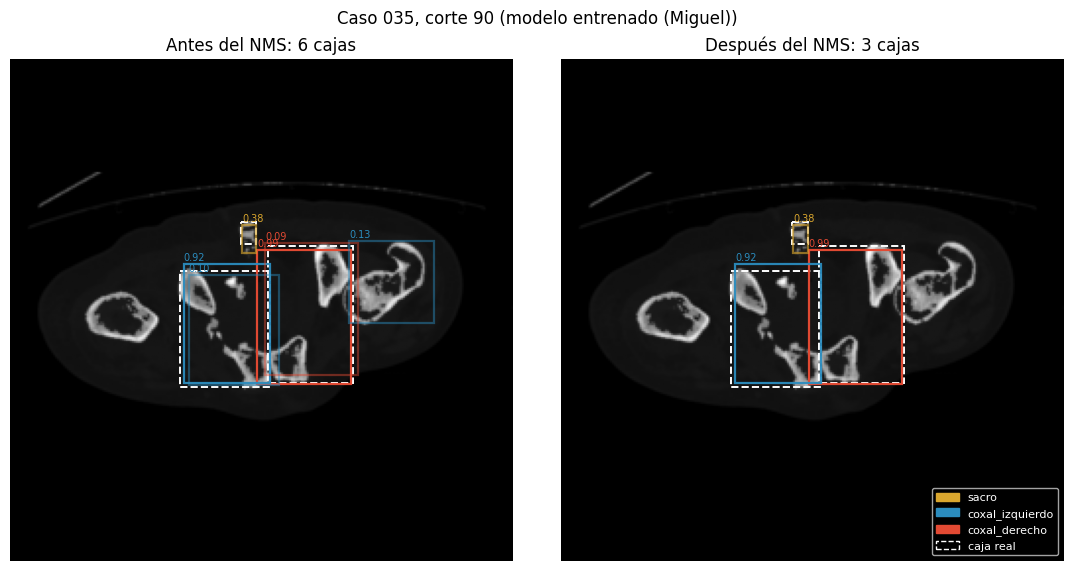

In [6]:
k = next((i for i, t in enumerate(targets_nms) if len(t["labels"]) == 3), 0)
raw_k = decode_predictions(salida_det[k:k + 1], score_thresh=CONFIG_PIPELINE["score_thresh"])[0]
final_k = postprocess(salida_det[k:k + 1], score_thresh=CONFIG_PIPELINE["score_thresh"],
                      nms_fn=nms_por_clase, **NMS_CONFIG)[0]
t = targets_nms[k]
figura_antes_despues(imagenes_nms[k], t, raw_k, final_k,
                     titulo=f"Caso {t['case_id']}, corte {t['slice_index']} ({origen_salida})",
                     path=FABIAN_EVIDENCE_DIR / "nms_antes_despues.png")
plt.show()

**Cómo leer la tabla.** Sin NMS, los duplicados cuentan como falsos positivos (`fp50`) y bajan el mAP. Con `max_det_per_class = 1` el valor de `iou_thresh` no cambia el resultado: al conservar solo la mejor caja de cada clase, el umbral nunca llega a aplicarse. Sin tope por clase, el umbral sí importa. La configuración se elige comparando estas filas en `val`.

## 4. Cabeza de pertenencia: etapa D de entrenamiento

La tercera cabeza recibe el mapa compartido `f4` (después de la compuerta CBAM) y la máscara de cada fragmento: promedia `f4` dentro del fragmento, agrega 6 rasgos de posición y tamaño y un MLP da 3 logits. La posición es la pista principal para izquierdo/derecho: los coxales son casi simétricos.

**Etapa D.** Se congela el tronco entrenado (backbone + CBAM) y se entrena solo esta cabeza con las máscaras **reales** de `train` (teacher forcing), igual que la etapa B entrenó solo el decoder. Como el tronco no cambia, `f4` se calcula una vez por corte y cada época solo pasa por la cabeza: cabe en CPU. Pérdida: entropía cruzada con pesos inversos a la frecuencia de cada clase en `train`. Selección: mejor F1 macro en `val`, con parada temprana.

Unidad de clasificación: un fragmento en un corte. Advertencia para entrenamientos futuros: un flip horizontal intercambia izquierdo y derecho; si se usa como aumento, intercambiar también las etiquetas 2 ↔ 3.

In [7]:
CABEZA_PATH = ENTRENAMIENTO_DIR / "cabeza_pertenencia.pt"
REENTRENAR_CABEZA = False          # True para volver a entrenar aunque ya exista CABEZA_PATH
MAX_CORTES_TRAIN = 2000            # submuestreo uniforme de train (memoria: ~130 KB por corte en float16)
MAX_CORTES_VAL = 800

cls_head = PertenenciaHead().to(DEVICE)
CABEZA_ENTRENADA = False

if not PESOS_ENTRENADOS:
    # Sin tronco entrenado no tiene sentido entrenar: prueba técnica de formas y gradiente hasta el backbone.
    idx_cls = [i for i, t in enumerate(targets_nms) if len(t["instance_ids"]) >= 2][:4]
    x_cls = torch.stack([imagenes_nms[i] for i in idx_cls]).to(DEVICE)
    masks_cls, b_idx_cls, labels_cls = targets_pertenencia([targets_nms[i]["instance_mask"] for i in idx_cls])
    f4_cls = componentes["cbam"](componentes["features_fn"](componentes["backbone"], x_cls)[-1])[0]
    loss_cls = perdida_pertenencia(cls_head(f4_cls, masks_cls.to(DEVICE), b_idx_cls.to(DEVICE)), labels_cls.to(DEVICE))
    loss_cls.backward()
    grad = next(p for p in componentes["backbone"].parameters() if p.grad is not None).grad.norm().item()
    print(f"Prueba técnica: pérdida {loss_cls.item():.4f} (ln 3 = {np.log(3):.4f}) | gradiente en el backbone {grad:.6f}")
    componentes["backbone"].zero_grad(set_to_none=True); componentes["cbam"].zero_grad(set_to_none=True)
    cls_head.zero_grad(set_to_none=True)
elif CABEZA_PATH.is_file() and not REENTRENAR_CABEZA:
    cls_head.load_state_dict(torch.load(CABEZA_PATH, map_location=DEVICE, weights_only=True))
    CABEZA_ENTRENADA = True
    print("Cabeza de pertenencia cargada desde", CABEZA_PATH.name)
else:
    def submuestreo(n, maximo):
        return sorted(set(np.linspace(0, n - 1, min(n, maximo)).astype(int).tolist()))

    ds_train_cls = PengwinDetectionDataset(split="train", as_torch=True)
    ds_val_cls = PengwinDetectionDataset(split="val", as_torch=True)
    t0 = time.time()
    print("Precalculando f4 de train con el tronco congelado...")
    cache_train = precalcular_cache_pertenencia(tronco, ds_train_cls, submuestreo(len(ds_train_cls), MAX_CORTES_TRAIN),
                                                batch_size=16, device=DEVICE)
    print("Precalculando f4 de val...")
    cache_val = precalcular_cache_pertenencia(tronco, ds_val_cls, submuestreo(len(ds_val_cls), MAX_CORTES_VAL),
                                              batch_size=16, device=DEVICE)
    ds_train_cls._image = ds_train_cls._label = ds_val_cls._image = ds_val_cls._label = None
    gc.collect()
    print(f"Caches listos en {time.time() - t0:.0f} s | instancias train: {cache_train['label'].shape[0]} "
          f"| val: {cache_val['label'].shape[0]}")
    print("Instancias por clase en train (sacro, coxal izq., coxal der.):",
          torch.bincount(cache_train["label"], minlength=3).tolist())

    cls_head, historial_cls, mejor_cls = entrenar_pertenencia(cls_head, cache_train, cache_val, epochs=40, lr=1e-3,
                                                              batch_inst=256, paciencia=8, seed=SEED, device=DEVICE)
    torch.save(cls_head.state_dict(), CABEZA_PATH)
    historial_cls.to_csv(FABIAN_EVIDENCE_DIR / "historial_etapa_D_pertenencia.csv", index=False)
    CABEZA_ENTRENADA = True
    print(f"Mejor época {mejor_cls['epoch']}: F1 macro val {mejor_cls['val_f1_macro']:.3f} | "
          f"AUC val {mejor_cls['val_auc_macro_ovr']:.3f} | guardada en {CABEZA_PATH.name}")

    fig, ax = plt.subplots(1, 2, figsize=(11, 3.8), constrained_layout=True)
    ax[0].plot(historial_cls["epoch"], historial_cls["train_loss"], label="train")
    ax[0].plot(historial_cls["epoch"], historial_cls["val_loss"], label="val")
    ax[0].set_title("Pérdida de pertenencia"); ax[0].set_xlabel("época"); ax[0].legend()
    ax[1].plot(historial_cls["epoch"], historial_cls["val_f1_macro"], label="F1 macro")
    ax[1].plot(historial_cls["epoch"], historial_cls["val_auc_macro_ovr"], label="AUC macro OvR")
    ax[1].axhline(0.85, ls="--", c="gray", lw=1, label="objetivo 0,85")
    ax[1].set_title("Validación"); ax[1].set_xlabel("época"); ax[1].legend()
    fig.savefig(FABIAN_EVIDENCE_DIR / "curvas_etapa_D_pertenencia.png", dpi=150)
    plt.show()

componentes["cls_head"] = cls_head.eval()
print("Cabeza de pertenencia entrenada:", CABEZA_ENTRENADA)

Cabeza de pertenencia cargada desde cabeza_pertenencia.pt
Cabeza de pertenencia entrenada: True


## 5. Pipeline completo

`inferir_cortes` ejecuta, sin usar ninguna anotación: tronco → cabeza grid → **NMS** → priors con las cajas finales → decoder de instancias → **cabeza de pertenencia**. Por cada fragmento entrega su clase, sus probabilidades, la caja que lo contiene y dos alertas que no se corrigen en silencio: `conflicto_semantica` (la cabeza y el decoder no coinciden) y `conflicto_caja` (la cabeza y la caja no coinciden). Un fragmento que no cae en ninguna caja se **conserva** y se marca `sin_caja`.

`inferir_volumen` aplica lo mismo a todo el MHA, restaura las máscaras a la cuadrícula original, asocia instancias entre cortes y entrega `instance_volume` + `region_by_id`, que es la entrada de `measure_fragment_separations` (Daniela).

In [8]:
if DECODER_OK:
    salidas_demo = inferir_cortes(componentes, torch.stack(imagenes_nms[:4]).to(DEVICE))
    filas_demo = []
    for t, r in zip(targets_nms[:4], salidas_demo):
        filas_demo.append({
            "case_id": t["case_id"], "corte": t["slice_index"], "fragmentos_reales": len(t["instance_ids"]),
            "cajas_antes_nms": int(r["raw"]["boxes"].shape[0]), "cajas_despues_nms": int(r["final"]["boxes"].shape[0]),
            "fragmentos_predichos": len(r["instancias"]), "sin_caja": sum(d["sin_caja"] for d in r["instancias"]),
            "conflicto_semantica": sum(d["conflicto_semantica"] for d in r["instancias"]),
            "conflicto_caja": sum(d["conflicto_caja"] for d in r["instancias"]),
        })
    display(pd.DataFrame(filas_demo))
else:
    print("Pipeline por corte pendiente: falta el decoder entrenado (ver sección 2).")

Pipeline por corte pendiente: falta el decoder entrenado (ver sección 2).


In [9]:
# Volumen completo de un caso de val -> pertenencia 3D -> distancias (Daniela). En CPU tarda algunos minutos.
CORRER_VOLUMEN = PESOS_ENTRENADOS and DECODER_OK and CABEZA_ENTRENADA
CASO_VOLUMEN = sorted({t["case_id"] for t in targets_nms})[0]

if CORRER_VOLUMEN:
    from distancias_fragmentos import measure_fragment_separations
    fila = df[df["case_id"] == CASO_VOLUMEN].iloc[0]
    img_itk = sitk.ReadImage(str(resolve_repo_path(fila["image_path"])))
    t0 = time.time()
    resultado_volumen = inferir_volumen(componentes, sitk.GetArrayFromImage(img_itk).astype(np.float32),
                                        img_itk.GetSpacing(), batch_size=8, device=DEVICE, case_id=CASO_VOLUMEN)
    print(f"Volumen {CASO_VOLUMEN}: {len(resultado_volumen['cortes'])} cortes en {time.time() - t0:.0f} s | "
          f"fragmentos 3D: {len(resultado_volumen['fragmentos'])} | eventos de enlace: {len(resultado_volumen['eventos'])}")
    distancias_pred = measure_fragment_separations(
        resultado_volumen["instance_volume"], resultado_volumen["spacing_xyz"],
        case_id=CASO_VOLUMEN, region_by_id=resultado_volumen["region_by_id"])
    resultado_volumen["fragmentos"].to_csv(FABIAN_EVIDENCE_DIR / f"pertenencia_3d_caso_{CASO_VOLUMEN}.csv", index=False)
    resultado_volumen["cortes"].to_csv(FABIAN_EVIDENCE_DIR / f"cortes_caso_{CASO_VOLUMEN}.csv", index=False)
    distancias_pred.to_csv(FABIAN_EVIDENCE_DIR / f"distancias_predichas_caso_{CASO_VOLUMEN}.csv", index=False)
    display(resultado_volumen["fragmentos"])
    display(distancias_pred)
else:
    print("Volumen completo pendiente: requiere tronco, decoder y cabeza de pertenencia entrenados.")

Volumen completo pendiente: requiere tronco, decoder y cabeza de pertenencia entrenados.


## 6. Evaluación de la pertenencia

Unidad: **cada fragmento real en cada corte** de `val`. Dos modos:

- `modo="gt"`: la cabeza clasifica las máscaras reales. Aísla el error de clasificación.
- `modo="pred"`: la cabeza clasifica las instancias predichas, emparejadas con las reales por IoU ≥ 0,5 (Hungarian). Un fragmento real no emparejado queda **sin clase** y cuenta como error: no se excluye.

Se compara la cabeza contra dos reglas sin aprendizaje: la **mayoría semántica** del decoder y la **caja detectada** que contiene al fragmento. F1 macro y por clase sobre todas las instancias; AUC macro uno-contra-resto con las probabilidades de la cabeza (objetivo sugerido ≥ 0,85 en ambas). `test` solo se usa en la evaluación final con la configuración congelada.

In [10]:
if DECODER_OK:
    idx_eval = list(range(0, len(targets_nms), max(1, len(targets_nms) // 64)))[:64]
    tablas_eval = []
    for modo in ("gt", "pred"):
        partes = []
        for i in range(0, len(idx_eval), 16):
            sub = idx_eval[i:i + 16]
            partes.append(evaluar_pertenencia(componentes, torch.stack([imagenes_nms[j] for j in sub]).to(DEVICE),
                                              [targets_nms[j] for j in sub], modo=modo))
        detalle = pd.concat(partes, ignore_index=True)
        detalle.to_csv(FABIAN_EVIDENCE_DIR / f"pertenencia_detalle_val_{modo}.csv", index=False)
        resumen = resumen_evaluacion_pertenencia(detalle)
        resumen.insert(0, "modo", modo)
        tablas_eval.append(resumen)
    tabla_pertenencia = pd.concat(tablas_eval, ignore_index=True)
    tabla_pertenencia.insert(0, "pesos", "entrenados" if (PESOS_ENTRENADOS and CABEZA_ENTRENADA) else "SIN ENTRENAR")
    tabla_pertenencia.to_csv(FABIAN_EVIDENCE_DIR / "pertenencia_resumen_val.csv", index=False)
    display(tabla_pertenencia.round(3))
else:
    print("Evaluación con instancias predichas pendiente: falta el decoder entrenado (ver sección 2).")

Evaluación con instancias predichas pendiente: falta el decoder entrenado (ver sección 2).


## 7. Resultados en `val` y conclusiones (Fabián)

Modelo: checkpoint `best_C_conjunto` de Miguel (backbone `plus` + compuerta CBAM, decoder **sin** skip connections, etapa C, época 10). Muestra: 200 cortes positivos de `val` (casos 035, 037, 067, 071, 079), repartidos de forma uniforme. `test` no se usó.

**1. NMS propio por clase (sección 3).**

| | Sin NMS | Con NMS (`max_det_per_class = 1`) |
|---|---|---|
| Cajas por corte | 3,85 | 2,56 |
| Falsos positivos (IoU ≥ 0,5) | 296 | 45 |
| mAP@0.50 | 0,870 | 0,884 |
| mAP@[0.50:0.95] | 0,605 | 0,609 |
| IoU medio de las cajas acertadas | 0,854 | 0,851 |

- El NMS elimina el 85 % de los falsos positivos y sube el mAP. Cumple los objetivos de la sección 5 (mAP@0.50 ≥ 0,65; mAP@[0.50:0.95] ≥ 0,40; IoU ≥ 0,65).
- Con `max_det_per_class = 1`, `iou_thresh` entre 0,3 y 0,7 da resultados idénticos: al conservar solo la mejor caja por clase, el umbral no llega a aplicarse.
- Sin tope por clase, el mAP@0.50 sube solo a 0,888, pero los falsos positivos suben a 75 y se rompe la definición del target (una caja por región en cada corte). **Configuración elegida: `max_det_per_class = 1`.**
- El sacro es la clase más difícil (AP@0.50 = 0,78 frente a 0,93 y 0,95 de los coxales): sus cajas son más pequeñas.

**2. Cabeza de pertenencia, etapa D (sección 4).** 2.000 cortes de `train` (6.689 fragmentos) y 800 de `val` (2.493 fragmentos). Mejor época: 24 → **F1 macro 0,948 y AUC macro OvR 0,994**, por encima del objetivo de 0,85. Limitación: la pérdida de `train` cae casi a cero mientras la de `val` sube desde la época 5 (sobreajuste). El F1 de `val` se mantiene estable (~0,94), pero `val` tiene solo 5 pacientes: la medida definitiva es `test`.

**3. Pertenencia frente a reglas simples (sección 6), 200 fragmentos reales.**
- Con máscaras reales: la cabeza clasifica el 100 % de los fragmentos (exactitud 0,945); las reglas dejan 9 sin clase (exactitud 0,935) y alcanzan un F1 macro ligeramente mayor en los que sí clasifican (0,955 frente a 0,944), una diferencia dentro del ruido de esta muestra. La cabeza además entrega probabilidades (AUC 0,991), que las reglas no tienen.
- Con instancias predichas: los tres métodos caen a una exactitud cercana a 0,70 porque **58 de 200 fragmentos reales (29 %) no tienen una instancia predicha que los empareje** (IoU ≥ 0,5). El cuello de botella es la separación de instancias, no la clasificación.

**4. Volumen completo (sección 5).** El caso 035 pasa de punta a punta (373 cortes en 111 s en CPU) hasta `measure_fragment_separations`. Se obtienen **111 fragmentos 3D**, muchos de 1 corte y menos de 50 vóxeles, con 582 eventos de enlace: hay **sobresegmentación**. Por eso aparecen distancias de 115-135 mm que no corresponden a separaciones reales. Las distancias predichas de este modelo no deben compararse todavía con las de referencia.

**Pendientes y dependencias**
- Miguel: está reentrenando con el decoder con skip connections. Al tener el checkpoint nuevo hay que reentrenar la cabeza (`REENTRENAR_CABEZA = True`: el tronco cambia) y repetir este notebook. También reemplazar `predicted_boxes_top1` por `postprocess(..., nms_fn=nms_por_clase, max_det_per_class=1)`; es equivalente (prueba `NMSReemplazaAlMarcadorDeMiguel`) y no exige reentrenar.
- Annie y Daniela: revisar la sobresegmentación (umbrales del decoder ajustados con `val`, tamaño mínimo de fragmento validado con fragmentos reales pequeños, enlace 3D) antes de comparar distancias.
- Hoyos: usar las predicciones después del NMS, con `class_probs`, para el mAP y el AUC finales en `test`.
- Daniela: `letterbox_pair` usa el parámetro `mode` de Pillow, que se elimina en Pillow 13; no actualizar Pillow sin corregirlo (`requirements.txt` fija 11.3).